Using device: cpu


Saving archive.zip to archive.zip
Dataset extracted successfully!
Training folder: /content/dataset/seg_train/seg_train
Testing folder: /content/dataset/seg_test/seg_test

Dataset Information
-------------------
Number of classes: 6
Class names: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Training images: 14034
Testing images: 3000

Images in each class:
buildings : 2191
forest : 2271
glacier : 2404
mountain : 2512
sea : 2274
street : 2382


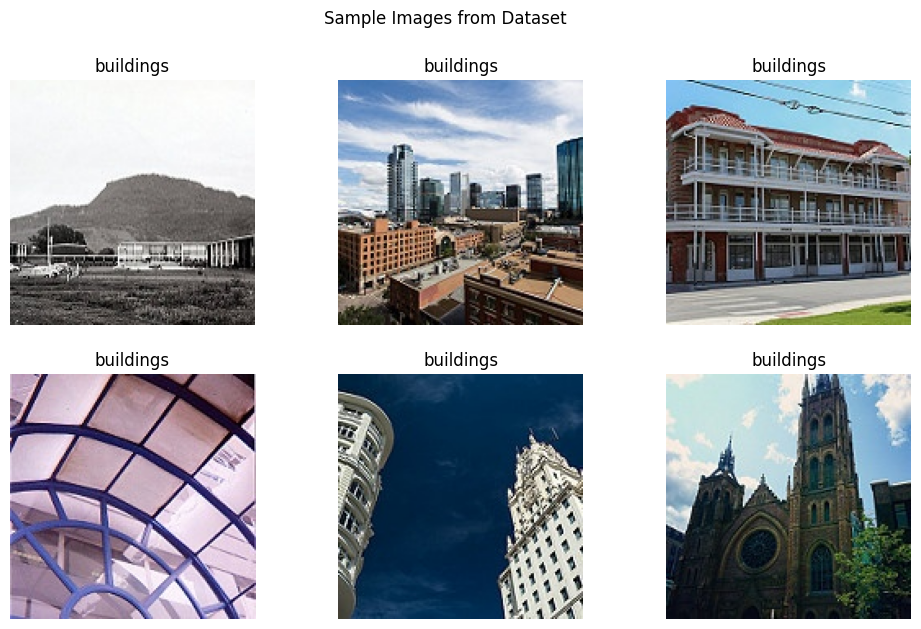


DataLoader Information
Training batches: 351
Validation batches: 88
Testing batches: 94

CNN Model Architecture
CustomCNN(
  (conv1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, di

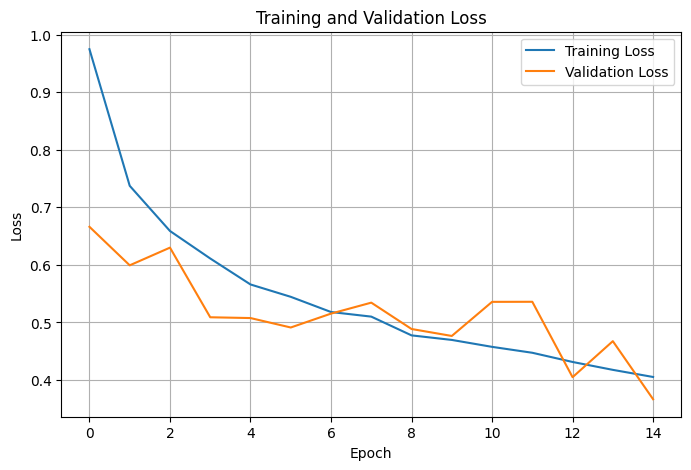

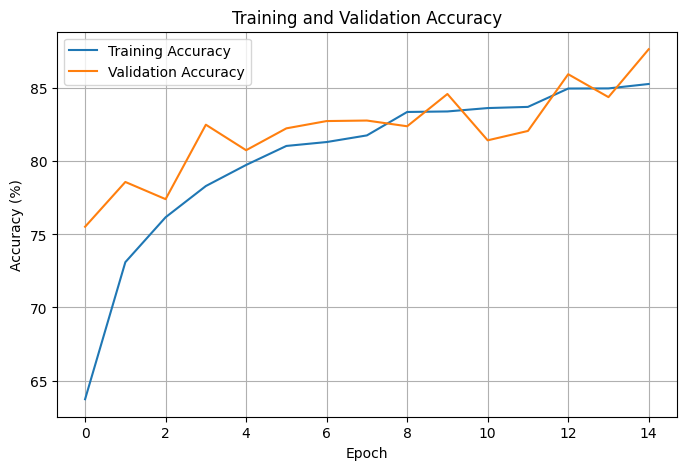

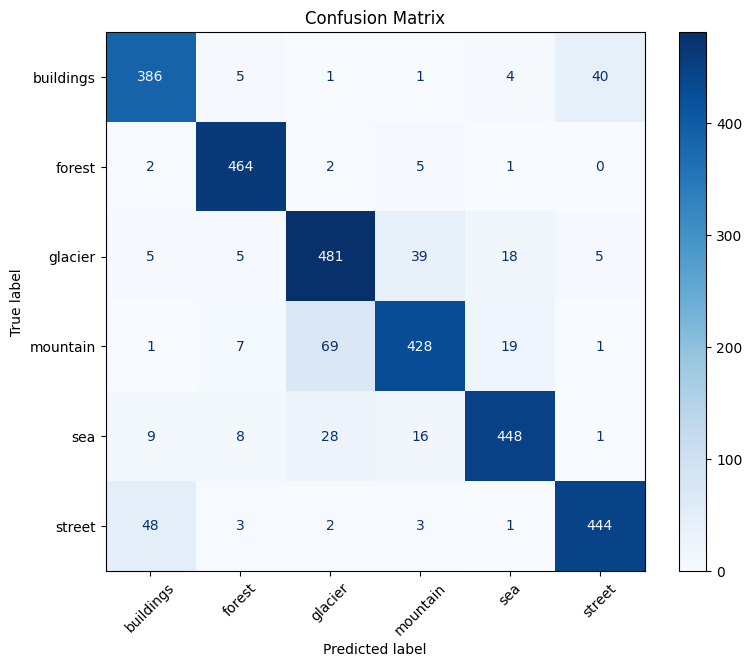


ANALYSIS AND DISCUSSION
-----------------------
Number of classes: 6
Training images: 11227
Validation images: 2807
Testing images: 3000
Best validation accuracy: 87.67 %
Final test accuracy: 88.37 %
Final test precision: 0.8841
Final test recall: 0.8837
Final test F1 score: 0.8835

Model saved successfully!
Saved model: /content/CNN_23-54217-3.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Assignment implementation completed!


In [1]:
# ============================================================
# CNN DEVELOPMENT ON CUSTOM DATASET
# Student ID: 23-54217-3
# Dataset: Intel Image Classification
# Framework: PyTorch
# ============================================================


# 1. IMPORT LIBRARIES

import os
import zipfile
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from google.colab import files

# Set random seed
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


# 2. LOAD AND EXPLORE DATASET

# Upload dataset ZIP file
uploaded = files.upload()

zip_file = next(iter(uploaded.keys()))

# Extract dataset
dataset_path = "/content/dataset"

os.makedirs(dataset_path, exist_ok=True)

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall(dataset_path)

print("Dataset extracted successfully!")


# Find the correct dataset folders
image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

def find_class_folder(root, folder_name):

    for path, folders, files_list in os.walk(root):

        if os.path.basename(path) == folder_name:

            valid_classes = []

            for folder in folders:

                folder_path = os.path.join(path, folder)

                if any(
                    file.lower().endswith(image_extensions)
                    for file in os.listdir(folder_path)
                ):
                    valid_classes.append(folder_path)

            if len(valid_classes) > 0:
                return path

    return None


train_dir = find_class_folder(dataset_path, "seg_train")
test_dir = find_class_folder(dataset_path, "seg_test")

print("Training folder:", train_dir)
print("Testing folder:", test_dir)

if train_dir is None or test_dir is None:
    raise FileNotFoundError(
        "Could not find seg_train or seg_test folders. "
        "Please check your dataset ZIP file."
    )


# Explore dataset
train_dataset = datasets.ImageFolder(train_dir)
test_dataset = datasets.ImageFolder(test_dir)

class_names = train_dataset.classes
num_classes = len(class_names)

print("\nDataset Information")
print("-------------------")
print("Number of classes:", num_classes)
print("Class names:", class_names)
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

print("\nImages in each class:")

for class_name in class_names:

    class_count = train_dataset.targets.count(
        train_dataset.class_to_idx[class_name]
    )

    print(class_name, ":", class_count)


# Display sample images
fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for i, ax in enumerate(axes.flat):

    if i < len(train_dataset):

        image, label = train_dataset[i]

        ax.imshow(image)
        ax.set_title(class_names[label])
        ax.axis("off")

plt.suptitle("Sample Images from Dataset")
plt.show()


# 3. DATA PREPROCESSING AND AUGMENTATION

IMAGE_SIZE = 150
BATCH_SIZE = 32

# Training transformations
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation and testing transformations
test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Create separate datasets for training and validation
train_data = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

validation_data = datasets.ImageFolder(
    train_dir,
    transform=test_transform
)

test_data = datasets.ImageFolder(
    test_dir,
    transform=test_transform
)

# Check class order
assert train_data.classes == test_data.classes, \
    "Training and testing class names do not match!"

# Split training data into 80% training and 20% validation
indices = np.arange(len(train_data))
targets = np.array(train_data.targets)

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=targets
)

train_subset = Subset(train_data, train_indices)
validation_subset = Subset(validation_data, val_indices)

# Create DataLoaders
train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

validation_loader = DataLoader(
    validation_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("\nDataLoader Information")
print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Testing batches:", len(test_loader))


# 4. DEFINE CUSTOM CNN ARCHITECTURE

class CustomCNN(nn.Module):

    def __init__(self, num_classes):

        super(CustomCNN, self).__init__()

        # First convolution block
        self.conv1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        # Second convolution block
        self.conv2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        # Third convolution block
        self.conv3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        # Fourth convolution block
        self.conv4 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        # Reduce feature map size
        self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 4))

        # Fully connected layers
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):

        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x)

        x = self.adaptive_pool(x)

        x = self.classifier(x)

        return x


# Create model
model = CustomCNN(num_classes).to(device)

print("\nCNN Model Architecture")
print(model)

# Display total trainable parameters
total_parameters = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("\nTotal Trainable Parameters:", total_parameters)

# Test model output shape
sample_input = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE).to(device)

with torch.no_grad():
    sample_output = model(sample_input)

print("Input Shape:", sample_input.shape)
print("Output Shape:", sample_output.shape)


# 5. TRAINING AND VALIDATION

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

EPOCHS = 15

# Store training results
train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

best_val_accuracy = 0.0

# Training loop
for epoch in range(EPOCHS):

    # Training mode
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backward pass
        loss.backward()

        # Update weights
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / total
    epoch_train_accuracy = 100 * correct / total


    # Validation mode
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in validation_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    epoch_val_loss = val_running_loss / val_total
    epoch_val_accuracy = 100 * val_correct / val_total

    # Save results
    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    train_accuracies.append(epoch_train_accuracy)
    val_accuracies.append(epoch_val_accuracy)

    # Save best model
    if epoch_val_accuracy > best_val_accuracy:

        best_val_accuracy = epoch_val_accuracy

        torch.save(
            model.state_dict(),
            "/content/best_CNN_model.pth"
        )

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} "
        f"Train Accuracy: {epoch_train_accuracy:.2f}% "
        f"Validation Loss: {epoch_val_loss:.4f} "
        f"Validation Accuracy: {epoch_val_accuracy:.2f}%"
    )


# Load best model
model.load_state_dict(
    torch.load("/content/best_CNN_model.pth", map_location=device)
)

print("\nBest Validation Accuracy:", best_val_accuracy)


# 6. EVALUATE MODEL ON TEST DATASET

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())


# Calculate evaluation metrics
test_accuracy = accuracy_score(all_labels, all_predictions)

precision = precision_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

print("\nTEST DATASET EVALUATION")
print("-----------------------")

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

print("\nClassification Report:\n")

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=class_names,
        zero_division=0
    )
)


# 7. VISUALIZATION: LOSS AND ACCURACY CURVES

# Training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid()
plt.show()


# Training and validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.legend()
plt.grid()
plt.show()


# Confusion matrix
cm = confusion_matrix(all_labels, all_predictions)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(9, 7))

display.plot(
    cmap="Blues",
    ax=ax,
    xticks_rotation=45
)

plt.title("Confusion Matrix")
plt.show()


# 8. ANALYSIS AND DISCUSSION OF RESULTS

print("\nANALYSIS AND DISCUSSION")
print("-----------------------")

print("Number of classes:", num_classes)
print("Training images:", len(train_subset))
print("Validation images:", len(validation_subset))
print("Testing images:", len(test_data))

print("Best validation accuracy:",
      round(best_val_accuracy, 2), "%")

print("Final test accuracy:",
      round(test_accuracy * 100, 2), "%")

print("Final test precision:", round(precision, 4))
print("Final test recall:", round(recall, 4))
print("Final test F1 score:", round(f1, 4))


# 9. SAVE TRAINED MODEL

model_save_path = "/content/CNN_23-54217-3.pth"

torch.save(
    model.state_dict(),
    model_save_path
)

print("\nModel saved successfully!")
print("Saved model:", model_save_path)

# Download trained model
files.download(model_save_path)

print("\nAssignment implementation completed!")